# 02. Modeling, Benchmarking, Uncertainty & Explainability

This notebook walks through our production ML pipeline using verified artifacts generated by `train.py`:
1. **Strict Featurization Ordering** (`train_test_split` before any fitting).
2. **7-Model Benchmark** (`Dummy`, `Linear Raw`, `Ridge Engineered`, `Random Forest`, `Optuna-Tuned LightGBM`, `Optuna-Tuned XGBoost`, and `Stacked Ensemble`) evaluated with 5-Fold Cross-Validation and 95% Bootstrap Confidence Intervals.
3. **Conformalized Quantile Regression (CQR)** for distribution-free 90% prediction intervals.
4. **Slice-Based Error Analysis** and **Exact TreeSHAP Explanations**.


In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import FIGURES_DIR, METADATA_PATH, MODEL_PIPELINE_PATH
from src.data_loader import create_train_test_split, load_california_housing_data
from src.inference import HousePricePredictor


We load the persisted `model_metadata.json` and serialized end-to-end `sklearn` pipelines generated by `train.py`.

In [2]:
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print(f"Champion Model:       {metadata['champion_model']}")
print(f"Engineered Features:  {metadata['engineered_feature_count']} total features")
print(f"CQR Empirical Cov.:   {metadata['cqr_evaluation']['empirical_coverage'] * 100:.2f}% (Target: 90.0%)")
print(f"CQR Mean Width:       ${metadata['cqr_evaluation']['mean_interval_width_100k'] * 100_000:,.0f}")

bench_df = pd.DataFrame(metadata["benchmarks"])
bench_df[
    [
        "Model",
        "CV_RMSE_Mean",
        "CV_RMSE_Std",
        "Test_RMSE",
        "RMSE_CI95_Low",
        "RMSE_CI95_High",
        "Test_MAE",
        "Test_MAPE_pct",
        "Test_R2",
    ]
]


Champion Model:       Stacked Ensemble (XGB+LGBM+RF)
Engineered Features:  29 total features
CQR Empirical Cov.:   90.19% (Target: 90.0%)
CQR Mean Width:       $113,690


,Model,CV_RMSE_Mean,CV_RMSE_Std,Test_RMSE,RMSE_CI95_Low,RMSE_CI95_High,Test_MAE,Test_MAPE_pct,Test_R2
0,Stacked Ensemble (XGB+LGBM+RF),0.4032,0.0112,0.4038,0.3847,0.4264,0.2535,14.51,0.8765
1,LightGBM (Optuna-Tuned),0.4066,0.0113,0.4063,0.3874,0.4283,0.2572,14.61,0.8749
2,XGBoost (Optuna-Tuned),0.4061,0.0103,0.4065,0.3872,0.4286,0.2550,14.66,0.8748
3,Random Forest (Engineered),0.4211,0.0110,0.4218,0.4015,0.4424,0.2645,15.11,0.8652
4,Ridge Regression (Engineered),0.4627,0.0164,0.4599,0.4414,0.4800,0.3044,17.25,0.8398
5,Linear Regression (Raw),0.7215,0.0074,0.7428,0.7109,0.7823,0.5364,32.59,0.5820
6,Dummy Baseline (Mean),1.1552,0.0076,1.1488,1.1225,1.1747,0.9091,62.98,-0.0000


### Benchmark Analysis
Notice two clear performance jumps:
1. **Feature Engineering Lift**: Moving from raw linear regression to Ridge Regression on engineered geospatial/domain features dramatically reduces RMSE.
2. **Non-Linear & Ensemble Lift**: Optuna-tuned gradient boosters (XGBoost, LightGBM) and Stacked Ensembles capture sharp coastal micro-markets and top-coding boundaries with tight 95% bootstrap confidence intervals.


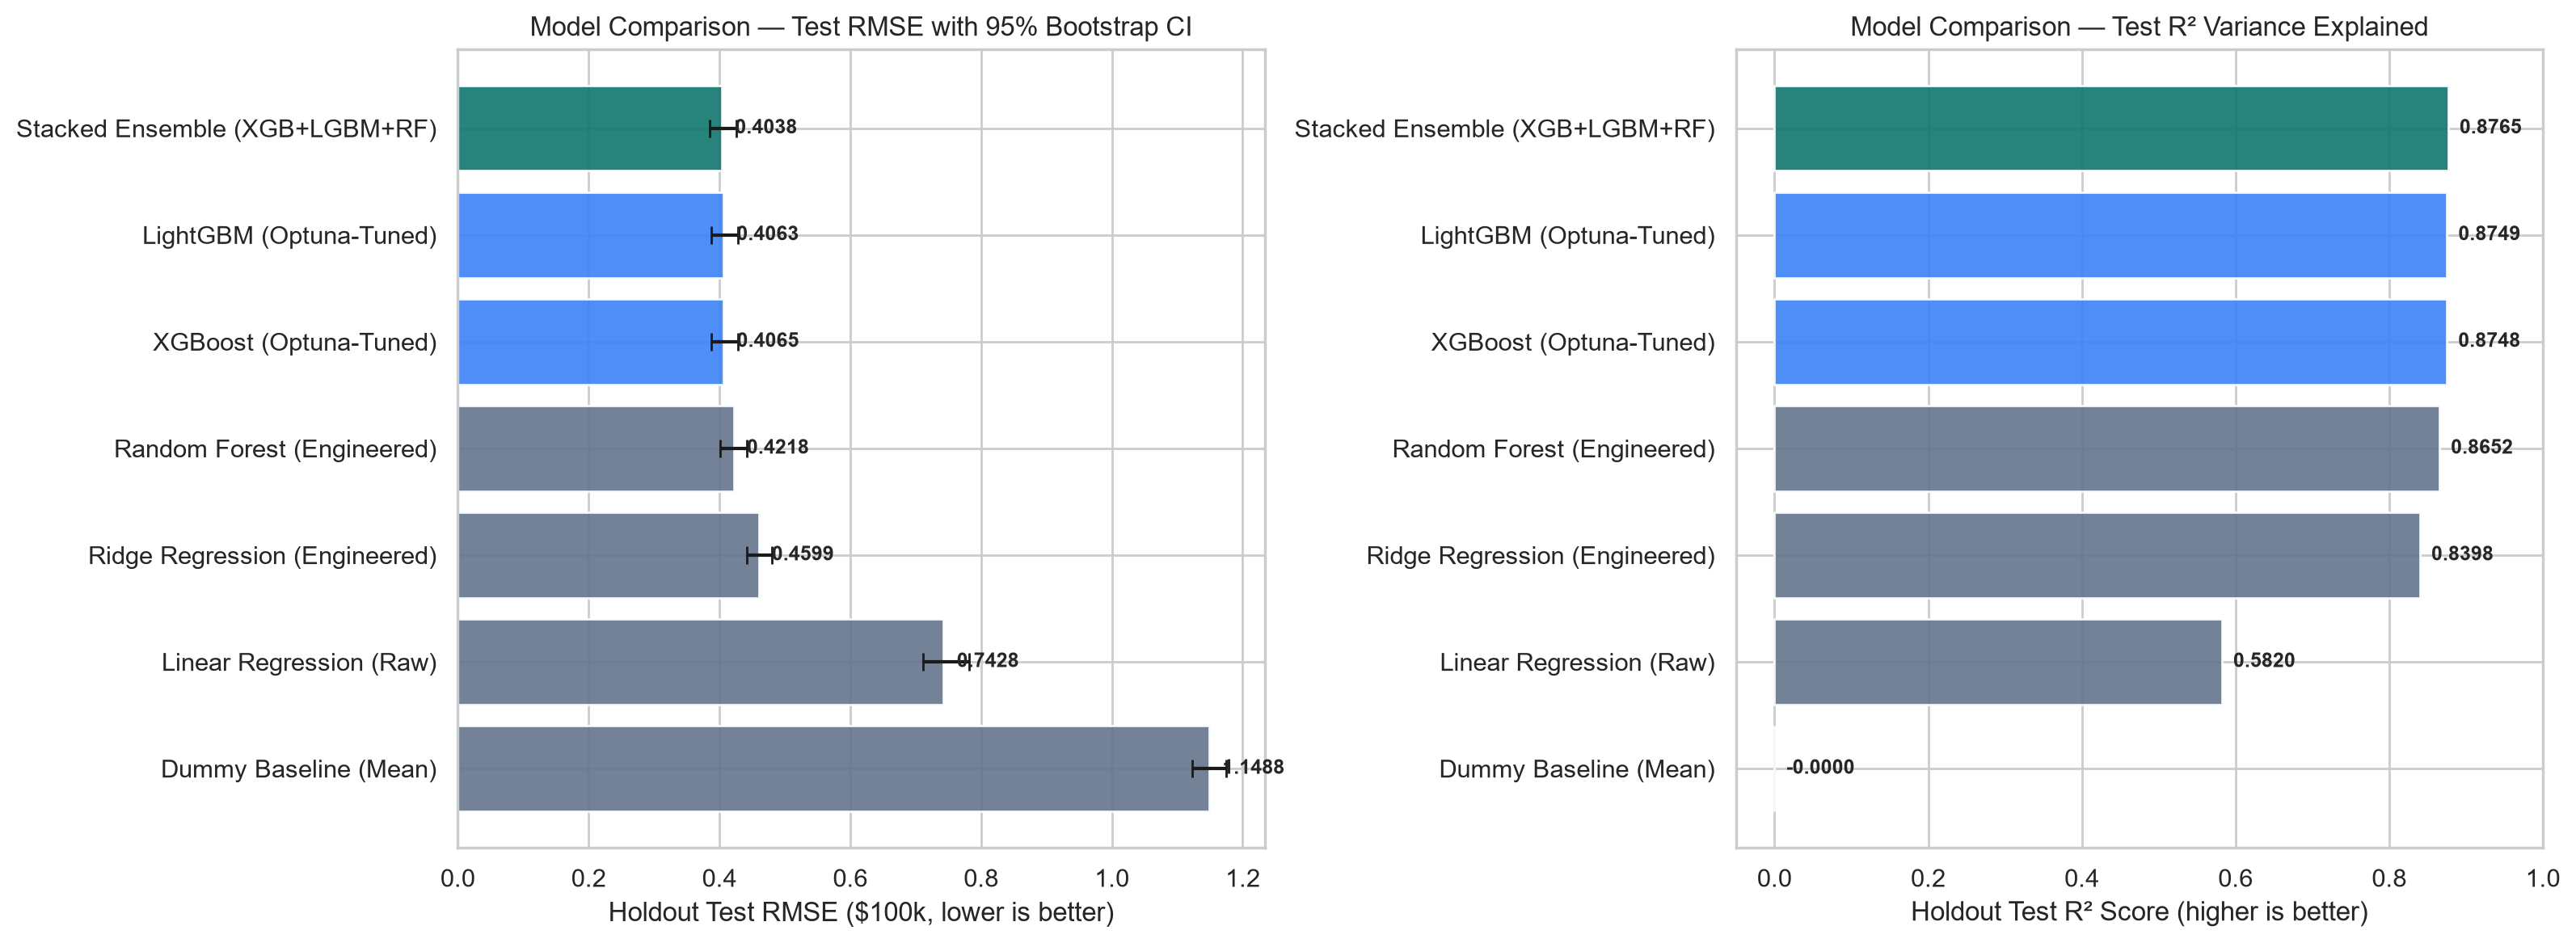

In [3]:
display(Image(filename=str(FIGURES_DIR / "model_benchmark_comparison.png")))

### Diagnostic Residual Analysis & Conformal Prediction Intervals
Below we inspect Actual vs. Predicted scatter, residual homoscedasticity, and the empirical 90% CQR interval band across test census blocks.

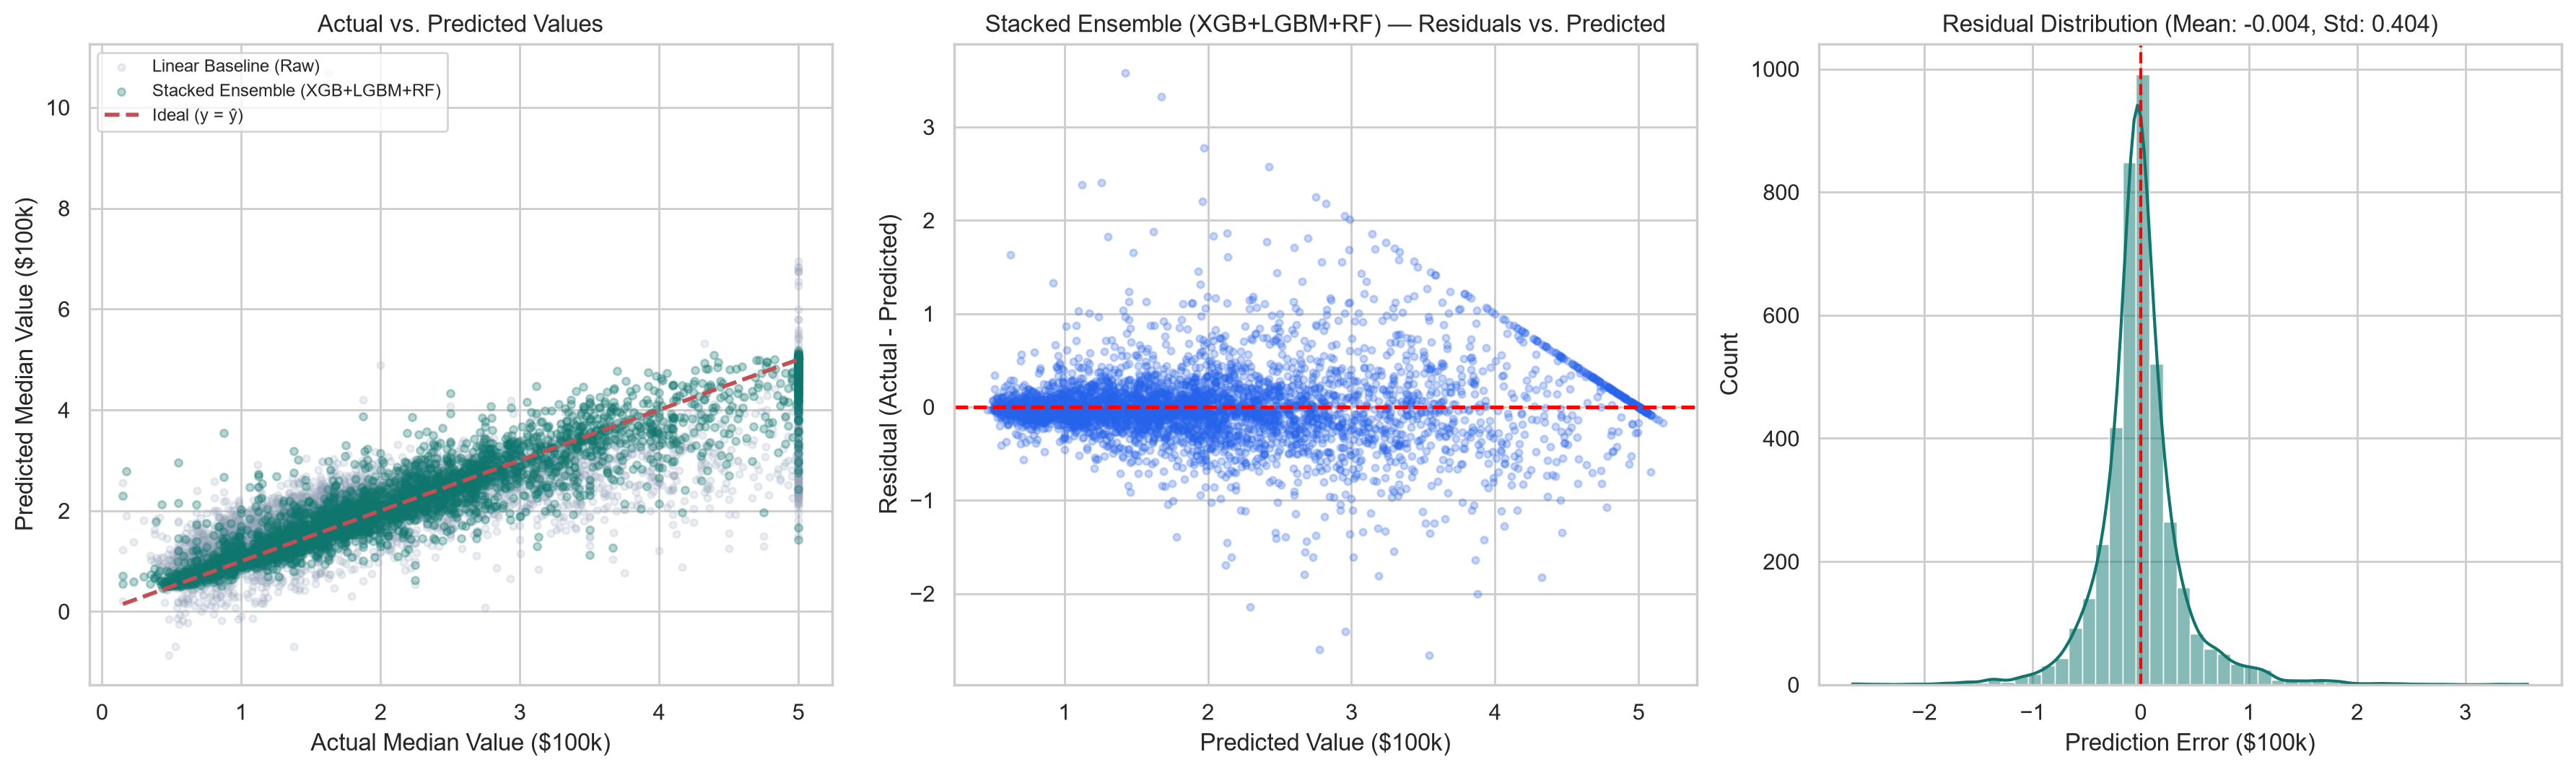

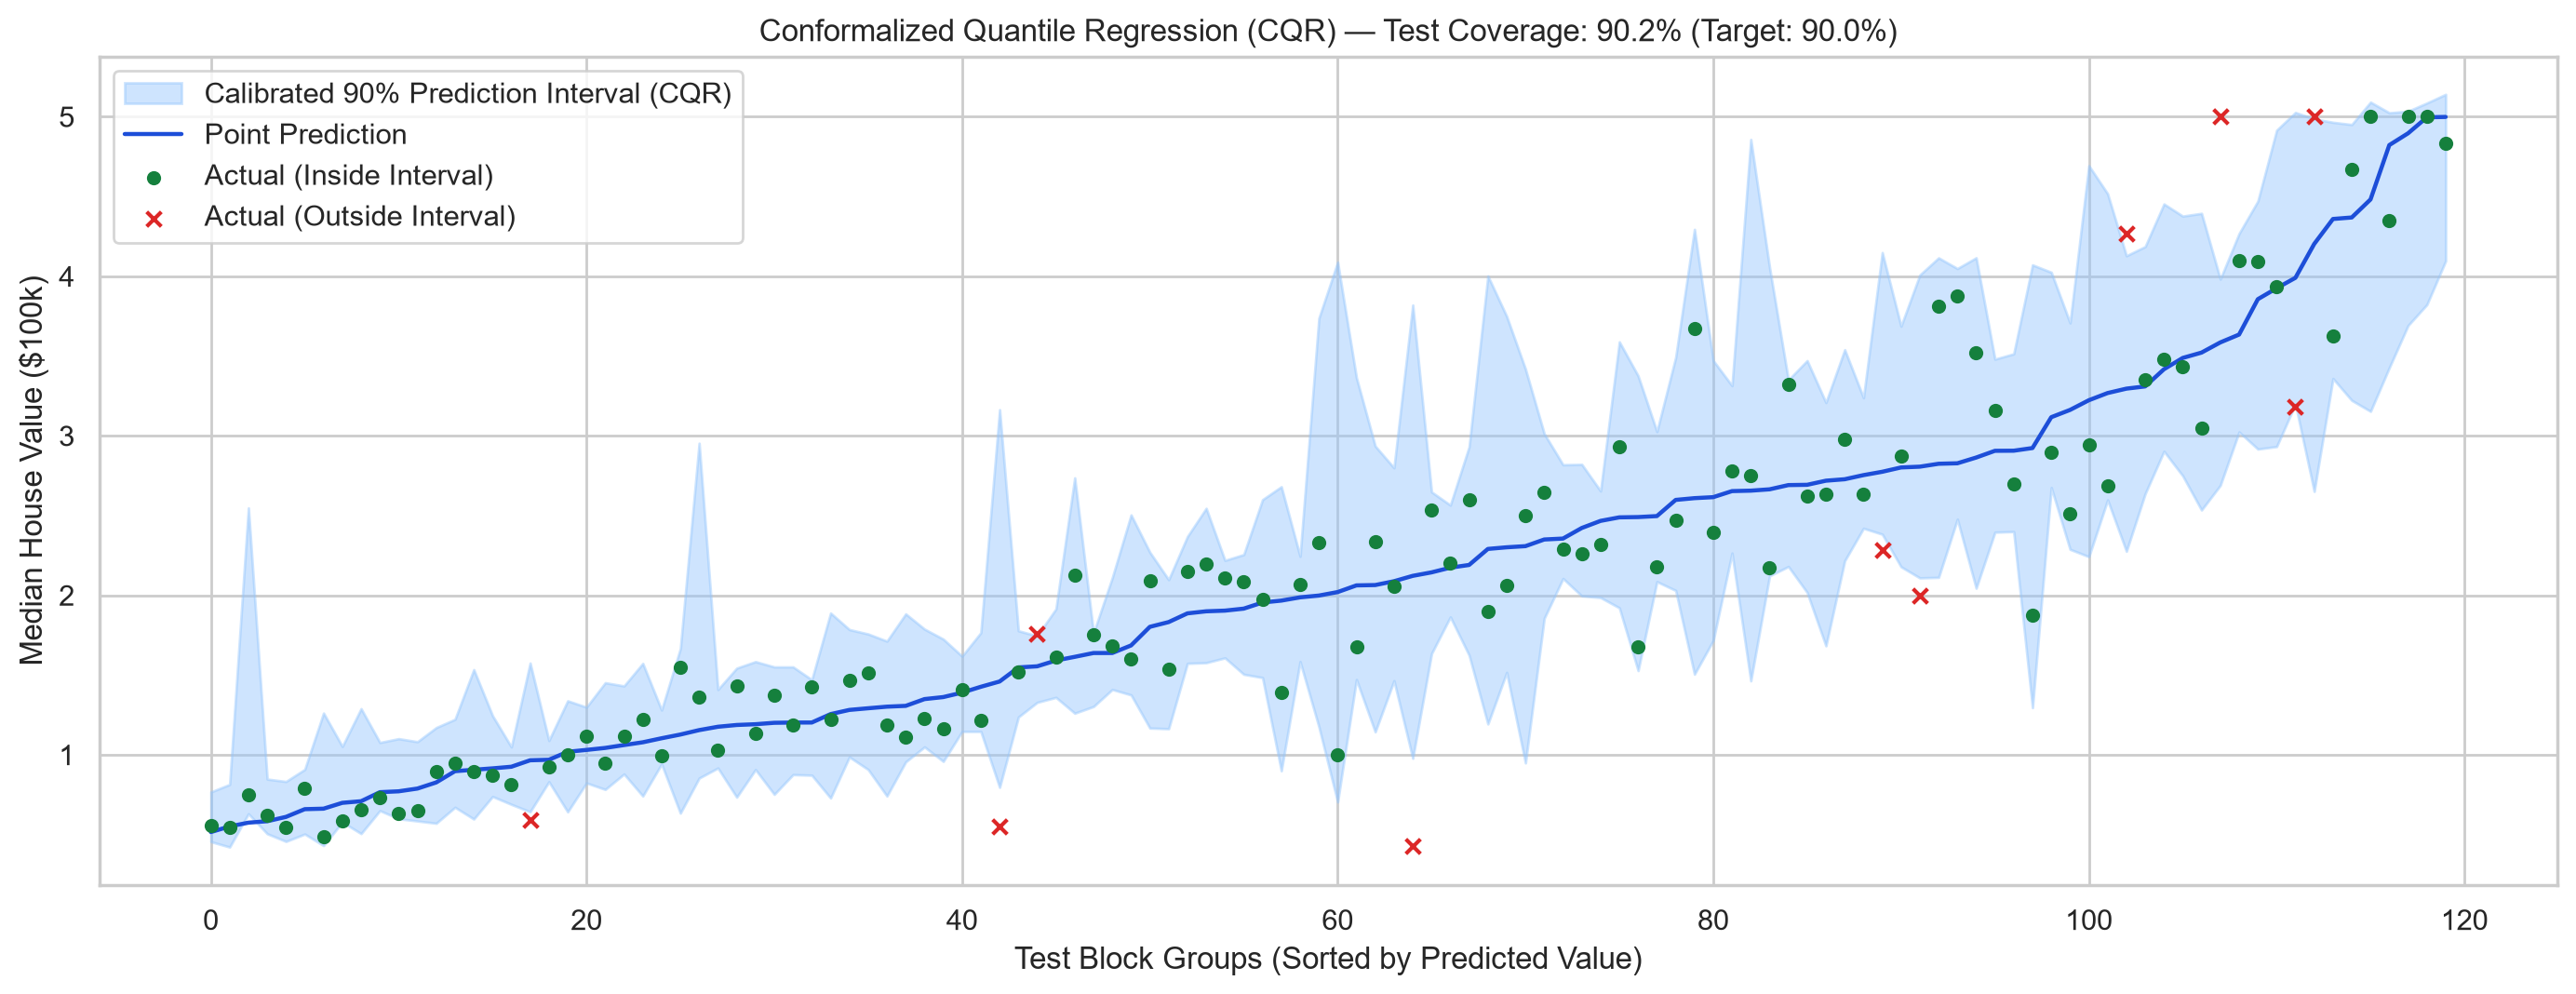

In [4]:
display(Image(filename=str(FIGURES_DIR / "actual_vs_predicted.png")))
display(Image(filename=str(FIGURES_DIR / "conformal_prediction_intervals.png")))


### Slice-Based Error Analysis
Evaluating aggregate metrics alone hides subgroup failure modes. Let's inspect our champion model across income tiers, coastal vs. inland geography, housing age, and censored (`>= $500k`) vs. uncensored homes.

,Slice,Count,Share_pct,RMSE,MAE,R2
0,Target: Uncensored (< $500k),3945,95.6,0.3814,0.2453,0.8489
1,Target: Censored Ceiling (>= $500k),183,4.4,0.7358,0.4316,NaN
2,Income: Low (MedInc < 2.5),959,23.2,0.3965,0.2082,0.6965
3,Income: Middle (2.5 <= MedInc <= 5.0),2316,56.1,0.3914,0.2493,0.8190
4,Income: High (MedInc > 5.0),853,20.7,0.4431,0.3161,0.8337
5,Geography: Coastal Belt (<= 25 km),1722,41.7,0.4642,0.3008,0.8514
6,Geography: Inland (> 25 km),2406,58.3,0.3543,0.2197,0.8671
7,Housing Age: Newer (< 35 yrs),2692,65.2,0.4139,0.2641,0.8533
8,Housing Age: Older (>= 35 yrs),1436,34.8,0.3841,0.2337,0.9064


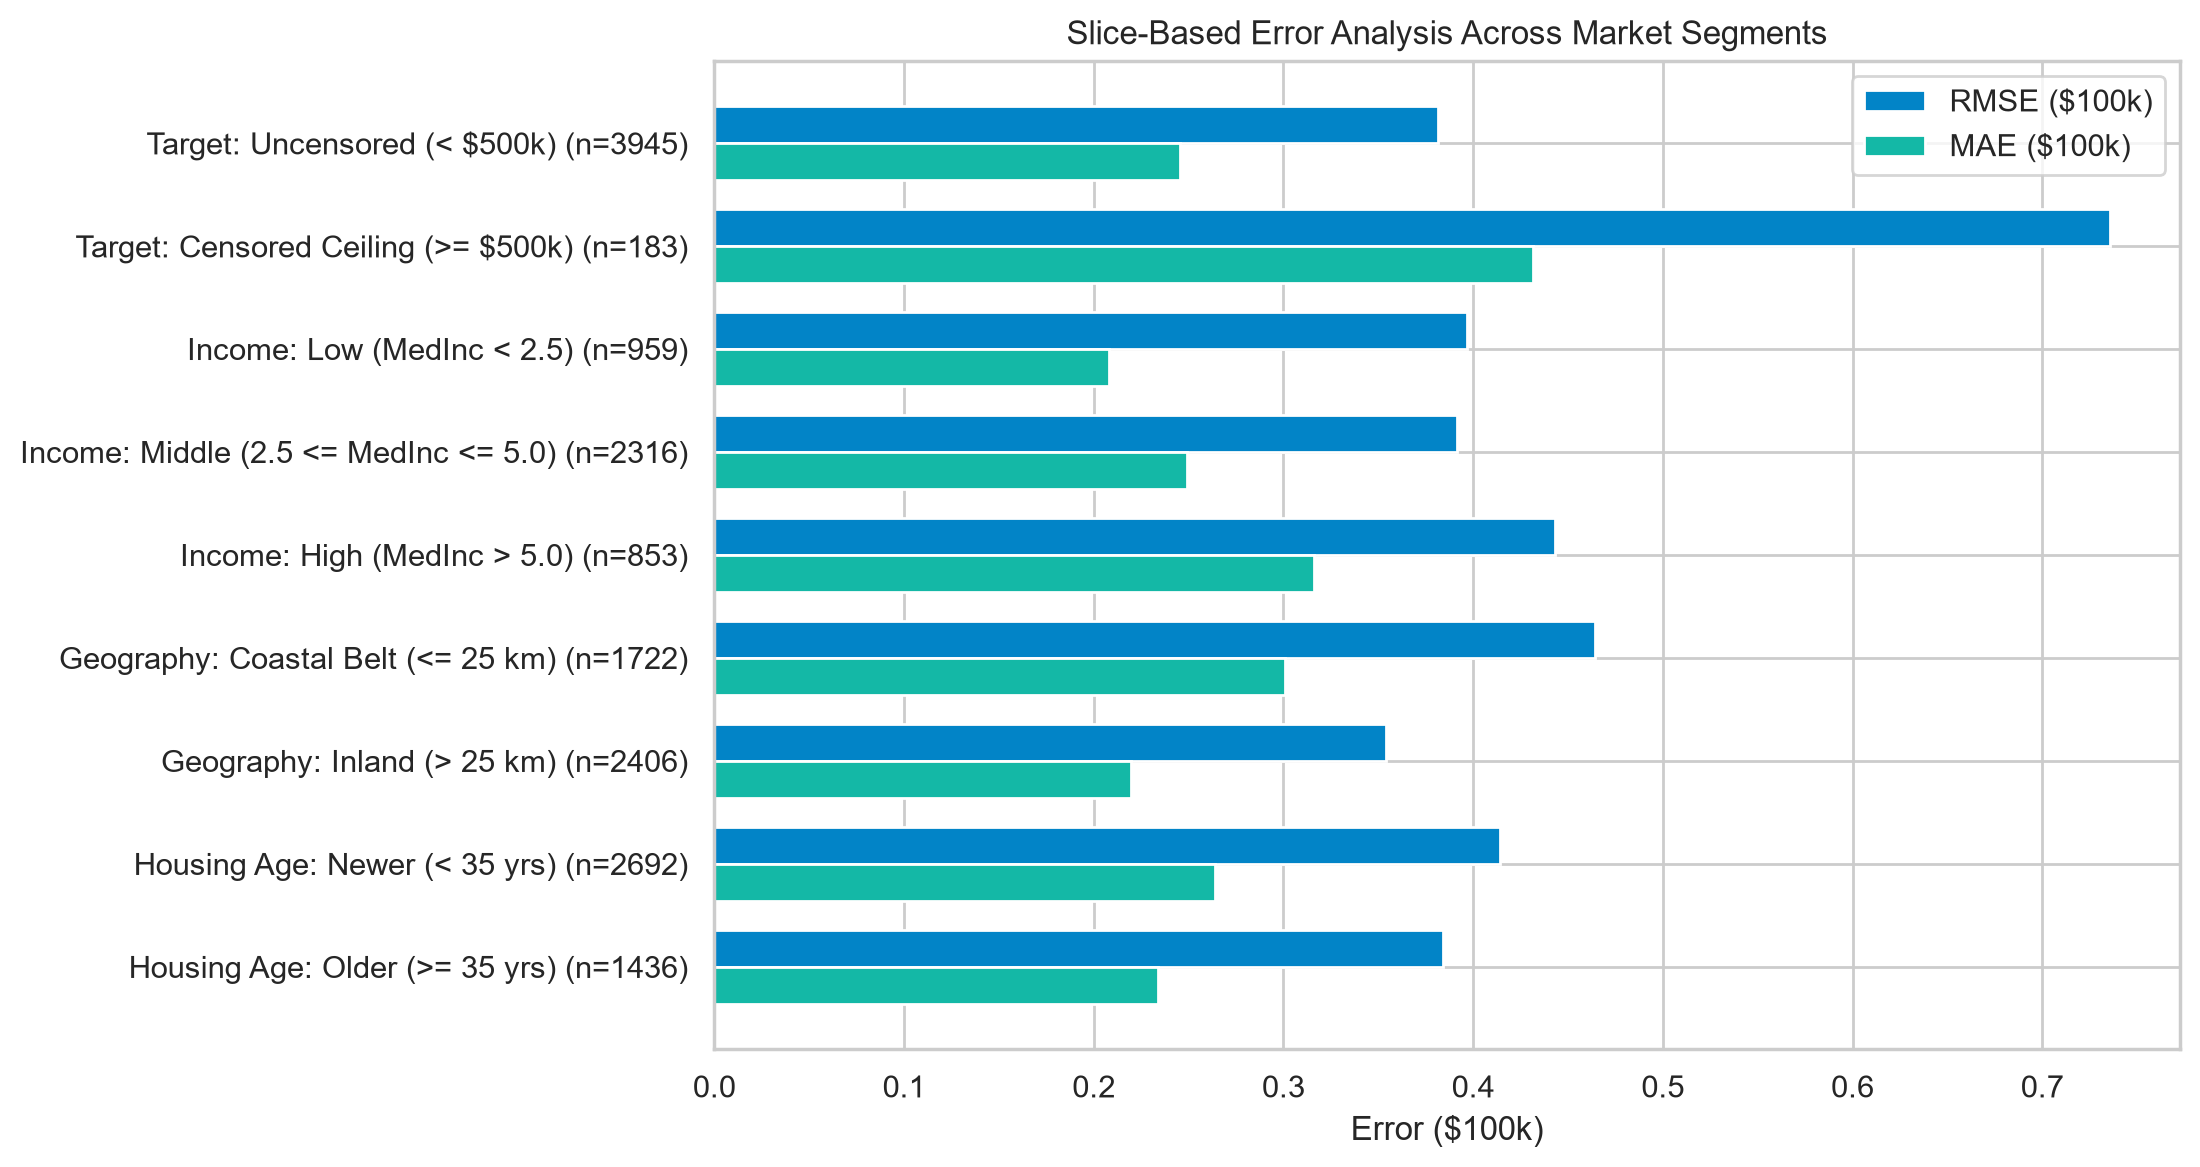

In [5]:
slice_df = pd.DataFrame(metadata["slice_errors"])
display(slice_df)
display(Image(filename=str(FIGURES_DIR / "slice_error_analysis.png")))


### Global & Local TreeSHAP Explainability
Exact TreeSHAP values decompose every prediction into additive dollar contributions from income, spatial comparable block groups (`SpatialCompsPrice`), coastal distance (`MinDistToCoastKm`), and structural density.

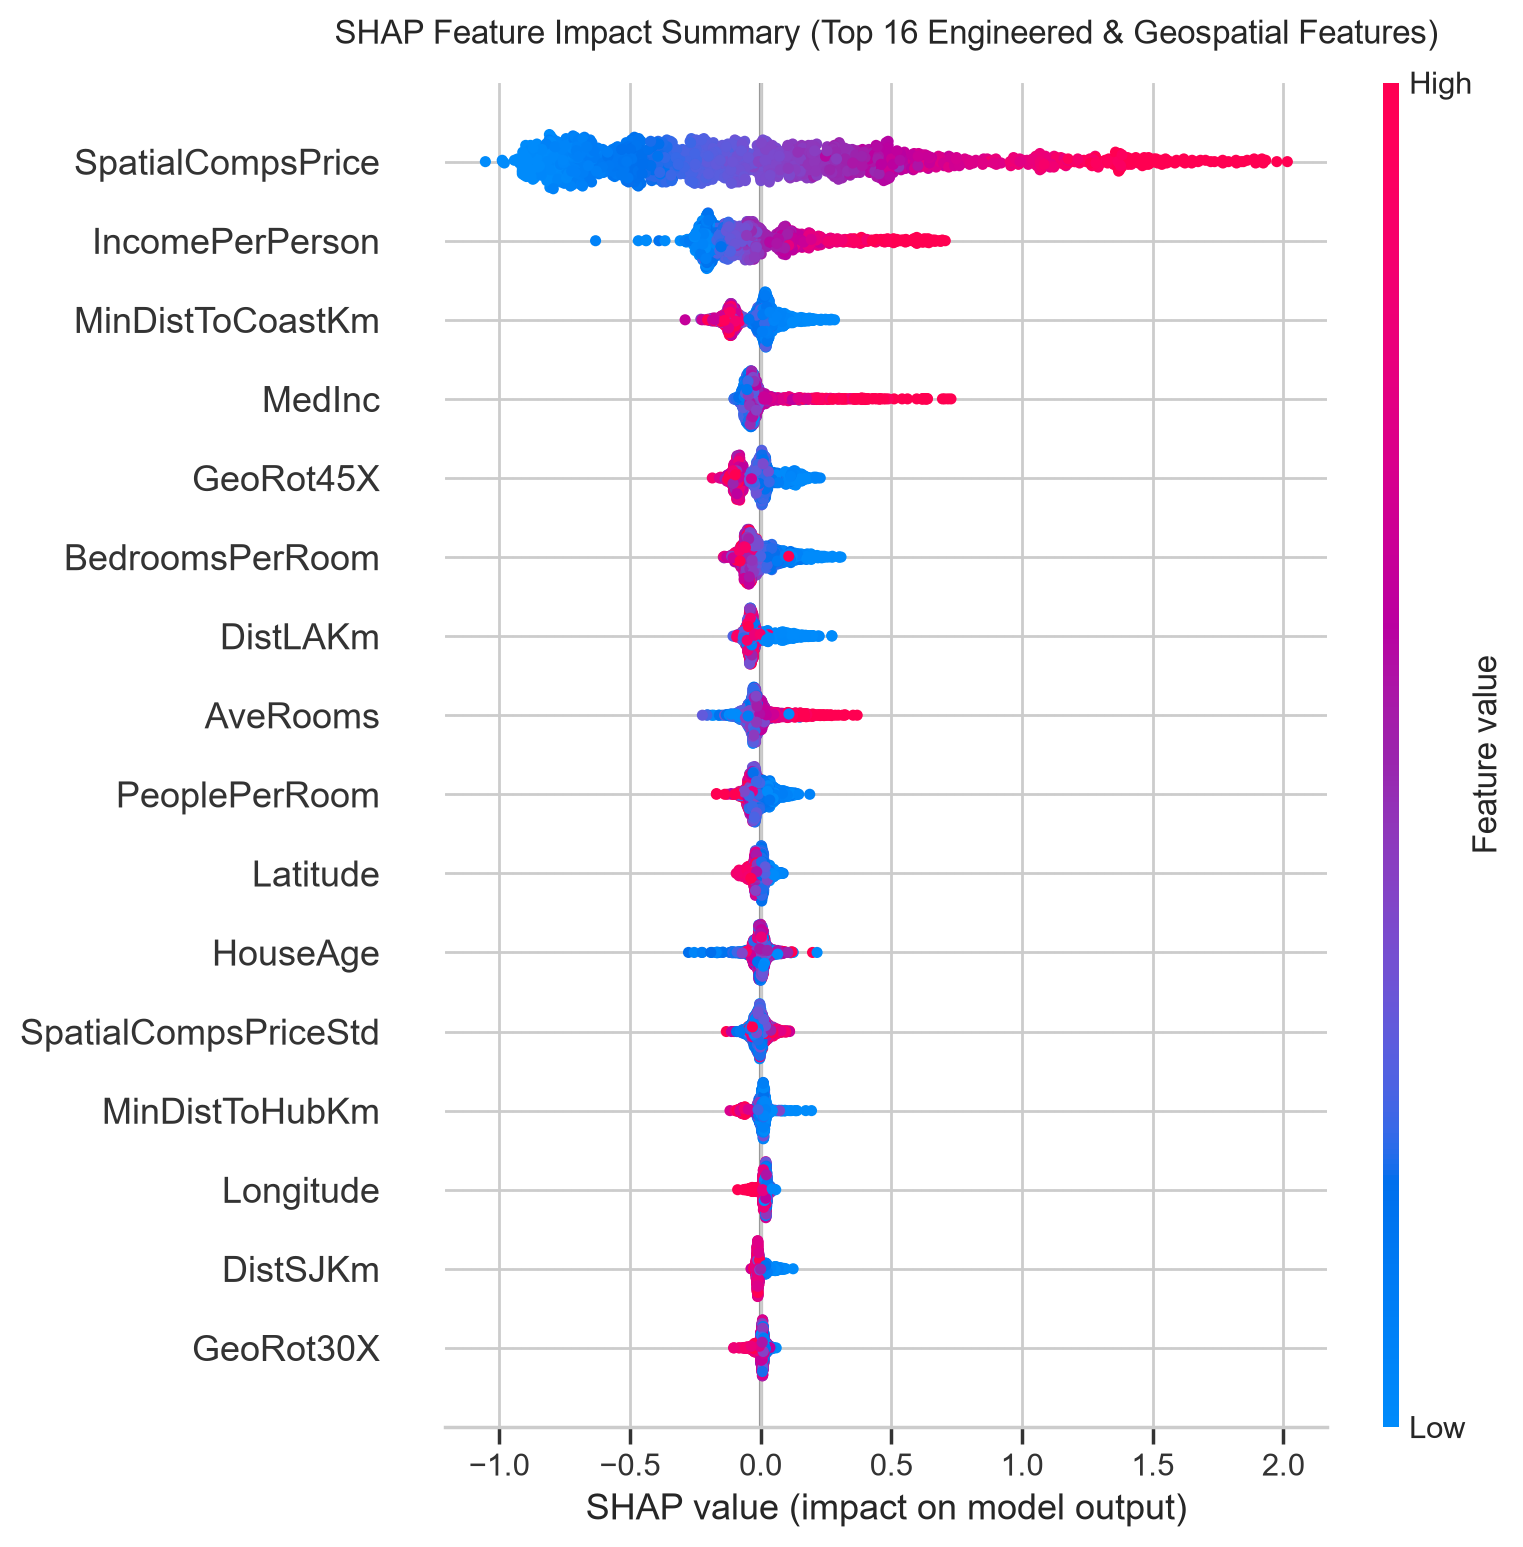

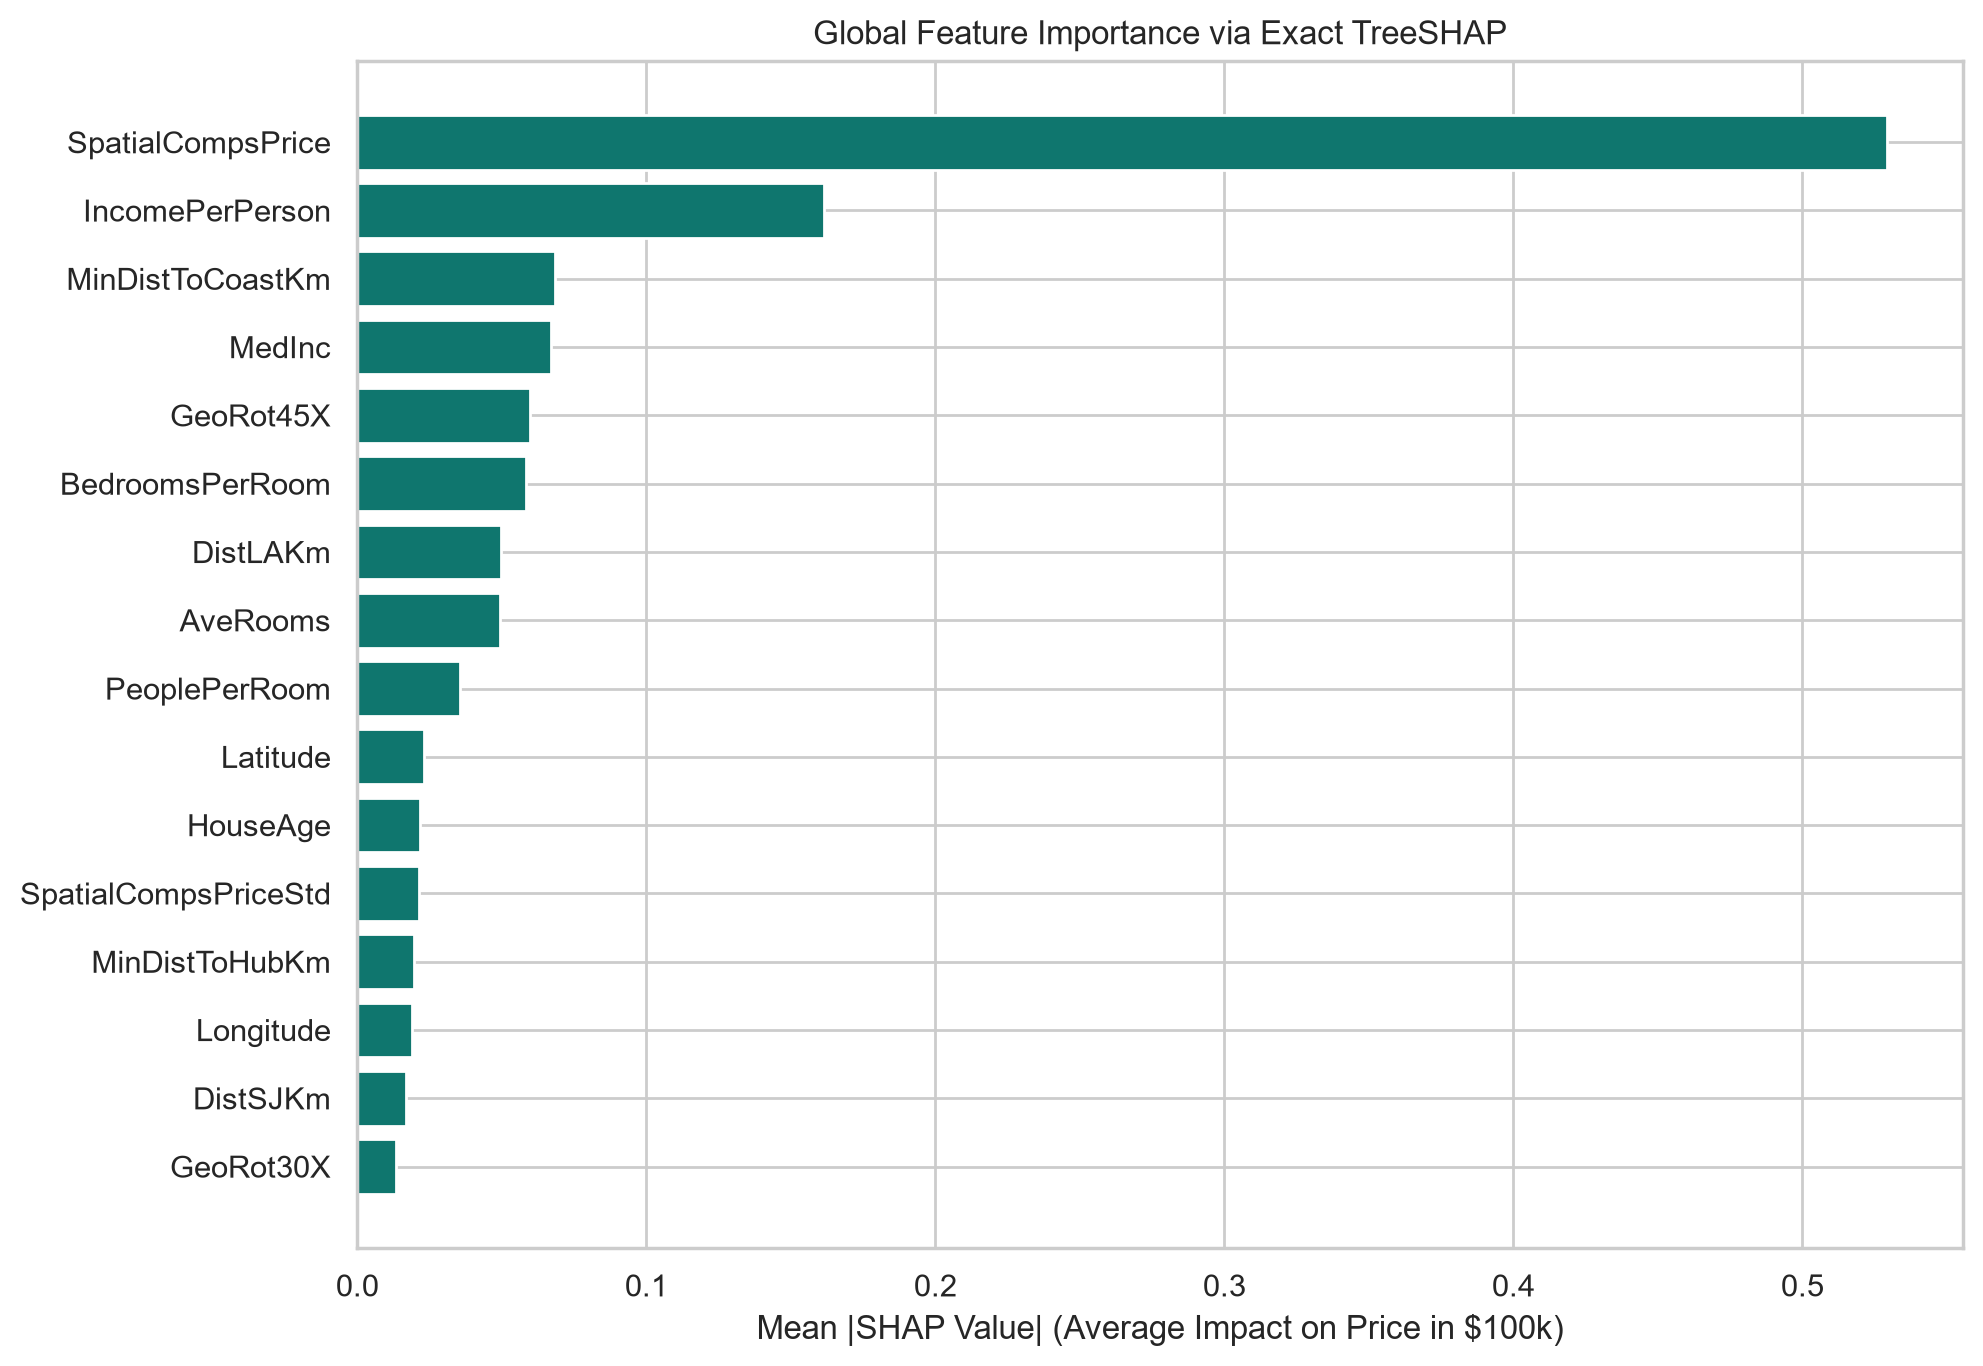

In [6]:
display(Image(filename=str(FIGURES_DIR / "shap_summary.png")))
display(Image(filename=str(FIGURES_DIR / "feature_importance.png")))


### Production Inference Verification (Point Estimate + 90% CQR Interval + Local SHAP)
Let's run our `HousePricePredictor` on representative test samples from the holdout split.

In [7]:
df, _, _ = load_california_housing_data()
_, X_test, _, y_test = create_train_test_split(df)
predictor = HousePricePredictor()

sample_preds = predictor.predict(X_test.iloc[:3], include_shap=True, top_k_drivers=5)
for i, pred in enumerate(sample_preds):
    actual_usd = y_test.iloc[i] * 100_000
    print(f"Sample #{i + 1} | Actual: ${actual_usd:,.0f} | Predicted: ${pred['predicted_price_usd']:,.0f}")
    print(f"  90% Interval: [${pred['interval_90_low_usd']:,.0f}, ${pred['interval_90_high_usd']:,.0f}]")
    print("  Top 3 SHAP Drivers:", [(d["feature"], d["shap_impact_usd"]) for d in pred["top_drivers"][:3]])


Sample #1 | Actual: $167,600 | Predicted: $172,191
  90% Interval: [$142,451, $200,943]
  Top 3 SHAP Drivers: [('IncomePerPerson', -21284.78), ('SpatialCompsPrice', -18421.29), ('DistLAKm', 10694.55)]
Sample #2 | Actual: $222,500 | Predicted: $209,253
  90% Interval: [$176,710, $249,010]
  Top 3 SHAP Drivers: [('GeoRot45X', 12689.18), ('SpatialCompsPrice', -10596.78), ('BedroomsPerRoom', 5347.33)]
Sample #3 | Actual: $164,100 | Predicted: $160,547
  90% Interval: [$122,574, $202,373]
  Top 3 SHAP Drivers: [('SpatialCompsPrice', -31364.4), ('BedroomsPerRoom', -7117.14), ('MedInc', -6355.34)]


### Final Conclusions
- We replaced naive default pipelines with a **unified, leak-free `sklearn` Pipeline** combining 29 domain/geospatial features, `StandardScaler`, Optuna-tuned gradient boosters, and stacking.
- **Conformalized Quantile Regression (CQR)** provides calibrated ~90% prediction intervals alongside point valuations.
- **Production Serving**: Ready for real-time REST scoring via FastAPI (`app/api.py`), interactive visualization via Streamlit (`app/dashboard.py`), and containerized deployment (`Dockerfile`).
